In [ ]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt, seaborn as sns

df = pd.read_csv("student-por.csv", sep=";")
print(df.shape)        # should be (649, 33)
print(df.head())
print(df.isnull().sum().sum())   # missing values, should be 0
print(df.duplicated().sum())     # duplicate rows
df.info()

(649, 33)
  school sex  age address famsize Pstatus  Medu  Fedu     Mjob      Fjob  ...  \
0     GP   F   18       U     GT3       A     4     4  at_home   teacher  ...   
1     GP   F   17       U     GT3       T     1     1  at_home     other  ...   
2     GP   F   15       U     LE3       T     1     1  at_home     other  ...   
3     GP   F   15       U     GT3       T     4     2   health  services  ...   
4     GP   F   16       U     GT3       T     3     3    other     other  ...   

  famrel freetime  goout  Dalc  Walc health absences  G1  G2  G3  
0      4        3      4     1     1      3        4   0  11  11  
1      5        3      3     1     1      3        2   9  11  11  
2      4        3      2     2     3      3        6  12  13  12  
3      3        2      2     1     1      5        0  14  14  14  
4      4        3      2     1     2      5        0  11  13  13  

[5 rows x 33 columns]
0
0
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 649 entries, 0 to 648
Da

In [ ]:
def grade_category(g):
    if g <= 9:  return 0   # Low (fail)
    elif g <= 14: return 1 # Medium
    else: return 2         # High

df["target"] = df["G3"].apply(grade_category)
print(df["target"].value_counts())

target
1    418
2    131
0    100
Name: count, dtype: int64


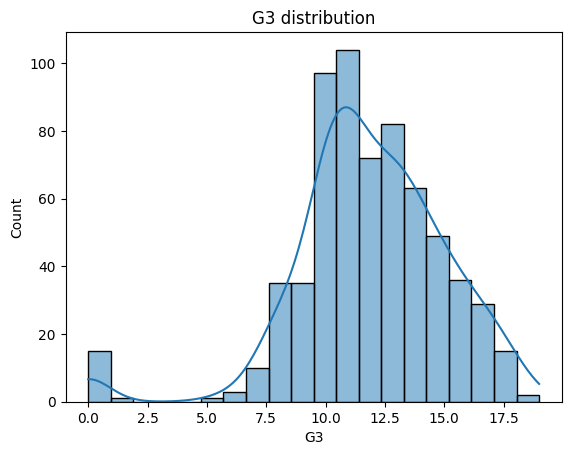

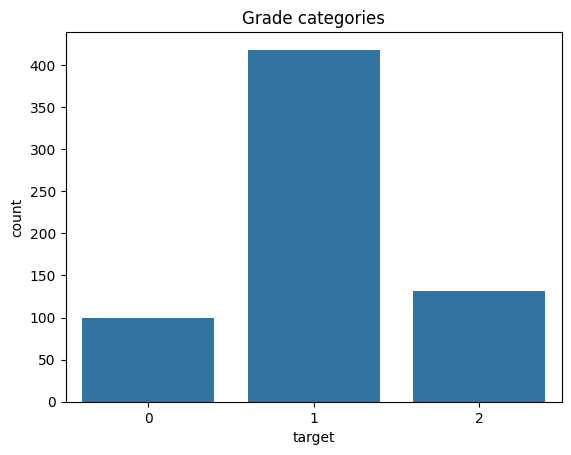

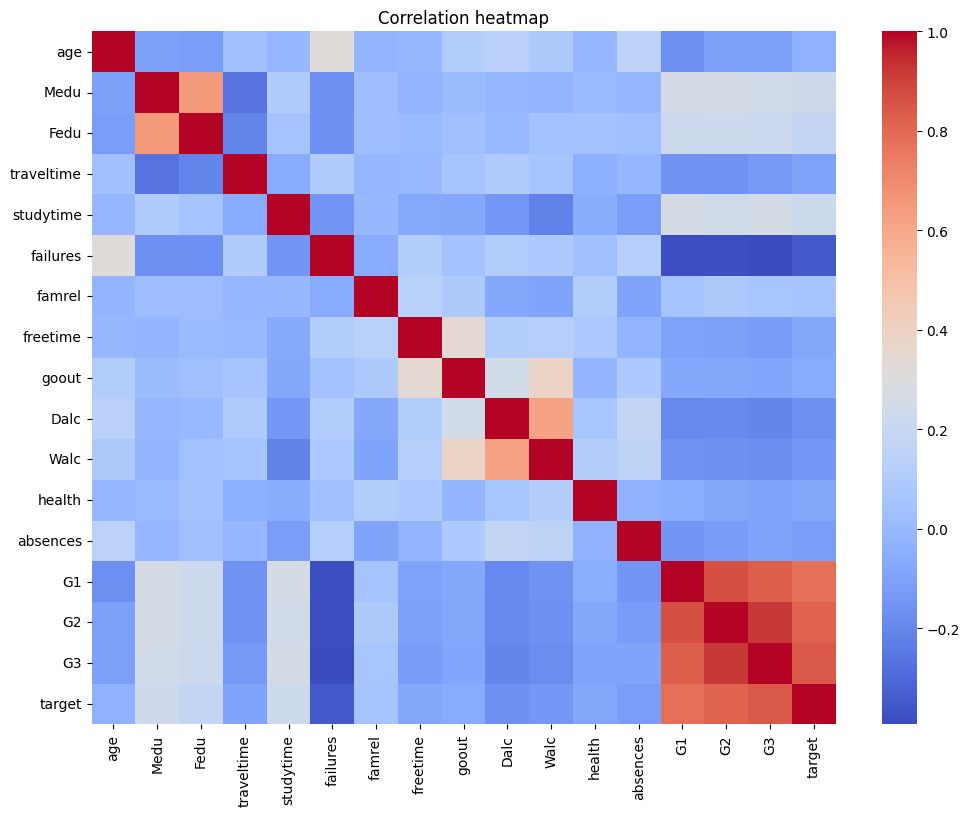

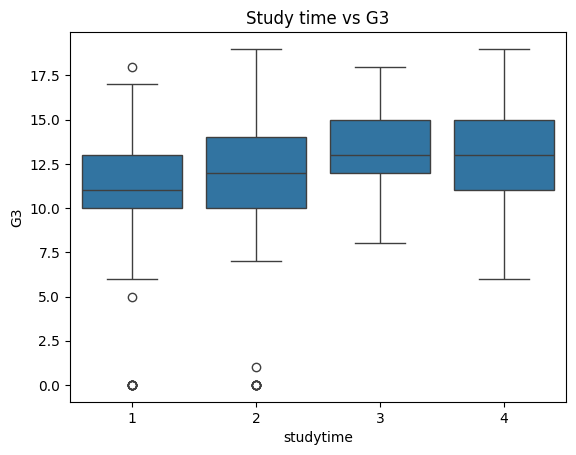

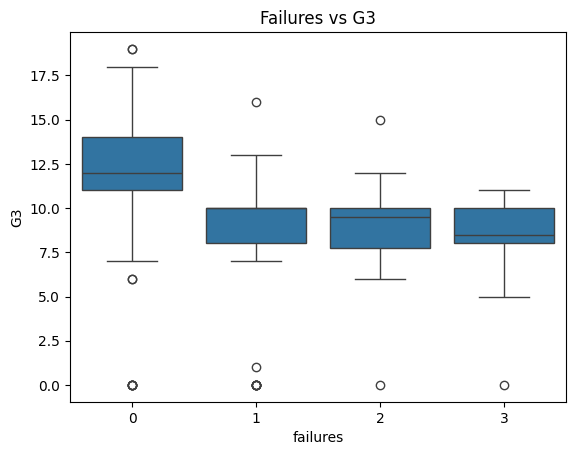

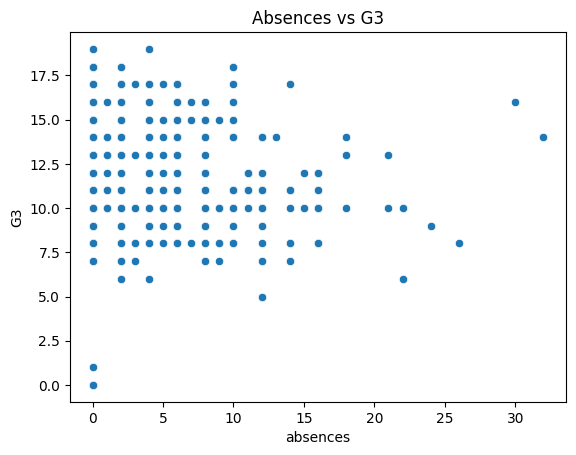

In [ ]:
# 1. Distribution of final grade
sns.histplot(df["G3"], bins=20, kde=True); plt.title("G3 distribution"); plt.show()

# 2. Class balance
sns.countplot(x="target", data=df); plt.title("Grade categories"); plt.show()

# 3. Correlation heatmap (numeric columns only)
plt.figure(figsize=(12,9))
sns.heatmap(df.select_dtypes("number").corr(), cmap="coolwarm", annot=False)
plt.title("Correlation heatmap"); plt.show()

# 4. Study time vs G3
sns.boxplot(x="studytime", y="G3", data=df); plt.title("Study time vs G3"); plt.show()

# 5. Failures and absences vs G3
sns.boxplot(x="failures", y="G3", data=df); plt.title("Failures vs G3"); plt.show()
sns.scatterplot(x="absences", y="G3", data=df); plt.title("Absences vs G3"); plt.show()

In [ ]:
df_enc = pd.get_dummies(df.drop(columns=["G3"]), drop_first=True)
print(df_enc.shape)

(649, 42)


G2           0.324089
G1           0.213510
failures     0.030726
absences     0.025451
famrel       0.023970
age          0.023325
health       0.022266
goout        0.022156
freetime     0.021532
Walc         0.020468
Fedu         0.018971
Medu         0.018714
school_MS    0.018226
studytime    0.016217
Dalc         0.014790
dtype: float64


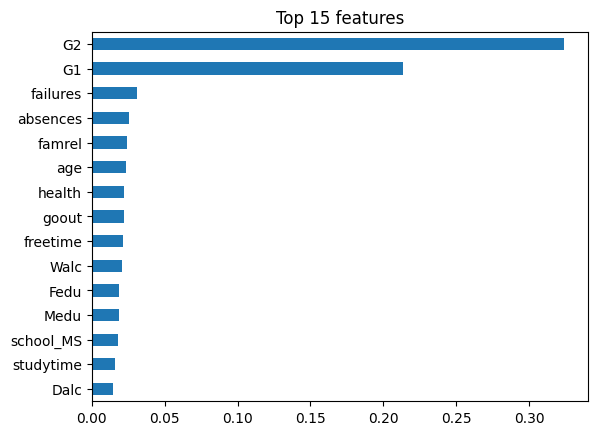

In [ ]:
from sklearn.ensemble import RandomForestClassifier

X_all = df_enc.drop(columns=["target"])
y = df_enc["target"]

rf = RandomForestClassifier(n_estimators=200, random_state=42)
rf.fit(X_all, y)

imp = pd.Series(rf.feature_importances_, index=X_all.columns).sort_values(ascending=False)
print(imp.head(15))
imp.head(15).plot(kind="barh").invert_yaxis(); plt.title("Top 15 features"); plt.show()

In [ ]:
df["higher"] = (df["higher"] == "yes").astype(int)
df["schoolsup"] = (df["schoolsup"] == "yes").astype(int)

features = ["G1","G2","studytime","failures","absences","age",
            "Medu","Fedu","goout","Dalc","health","higher","schoolsup","freetime"]

X = df[features]
y = df["target"]

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)

scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)   # learn scale from train only
X_test_s  = scaler.transform(X_test)        # apply the same scale to test

In [ ]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

def build_model(units1=64, units2=32, dropout=0.3, lr=0.001):
    model = keras.Sequential([
        layers.Input(shape=(X_train_s.shape[1],)),
        layers.Dense(units1, activation="relu"),
        layers.Dropout(dropout),
        layers.Dense(units2, activation="relu"),
        layers.Dropout(dropout),
        layers.Dense(3, activation="softmax")
    ])
    model.compile(optimizer=keras.optimizers.Adam(learning_rate=lr),
                  loss="sparse_categorical_crossentropy",
                  metrics=["accuracy"])
    return model

model = build_model()
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 64)             │           960 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 3)              │            99 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,139 (12.26 KB)

 Trainable params: 3,139 (12.26 KB)

 Non-trainable params: 0 (0.00 B)

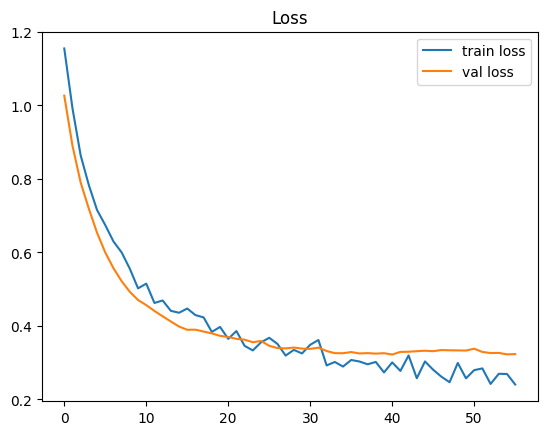

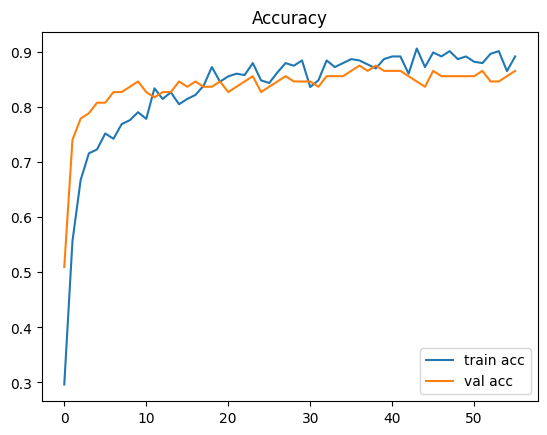

In [ ]:
early_stop = keras.callbacks.EarlyStopping(
    monitor="val_loss", patience=15, restore_best_weights=True)

history = model.fit(X_train_s, y_train, validation_split=0.2,
                    epochs=200, batch_size=32,
                    callbacks=[early_stop], verbose=0)

plt.plot(history.history["loss"], label="train loss")
plt.plot(history.history["val_loss"], label="val loss")
plt.legend(); plt.title("Loss"); plt.show()

plt.plot(history.history["accuracy"], label="train acc")
plt.plot(history.history["val_accuracy"], label="val acc")
plt.legend(); plt.title("Accuracy"); plt.show()

In [ ]:
import itertools
results = []
for u1, u2, d, lr, bs in itertools.product(
        [32, 64, 128], [16, 32], [0.2, 0.4], [0.001, 0.01], [16, 32]):
    m = build_model(u1, u2, d, lr)
    h = m.fit(X_train_s, y_train, validation_split=0.2, epochs=100,
              batch_size=bs, callbacks=[early_stop], verbose=0)
    results.append((u1, u2, d, lr, bs, max(h.history["val_accuracy"])))

res = pd.DataFrame(results, columns=["units1","units2","dropout","lr","batch","val_acc"])
print(res.sort_values("val_acc", ascending=False).head(5))

    units1  units2  dropout     lr  batch   val_acc
11      32      32      0.2  0.010     32  0.913462
44     128      32      0.4  0.001     16  0.903846
22      64      16      0.4  0.010     16  0.903846
17      64      16      0.2  0.001     32  0.903846
19      64      16      0.2  0.010     32  0.894231


In [ ]:
best = res.sort_values("val_acc", ascending=False).iloc[0]
model = build_model(int(best.units1), int(best.units2), best.dropout, best.lr)
history = model.fit(X_train_s, y_train, validation_split=0.2, epochs=200,
                    batch_size=int(best.batch), callbacks=[early_stop], verbose=0)

5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 38ms/step
DNN accuracy: 0.7230769230769231
              precision    recall  f1-score   support

         Low       0.00      0.00      0.00        20
      Medium       0.70      1.00      0.82        84
        High       1.00      0.38      0.56        26

    accuracy                           0.72       130
   macro avg       0.57      0.46      0.46       130
weighted avg       0.65      0.72      0.64       130



/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


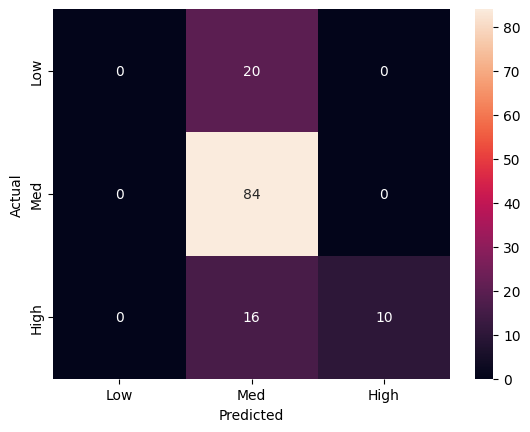

In [ ]:
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score

y_pred = np.argmax(model.predict(X_test_s), axis=1)
print("DNN accuracy:", accuracy_score(y_test, y_pred))
print(classification_report(y_test, y_pred, target_names=["Low","Medium","High"]))

sns.heatmap(confusion_matrix(y_test, y_pred), annot=True, fmt="d",
            xticklabels=["Low","Med","High"], yticklabels=["Low","Med","High"])
plt.xlabel("Predicted"); plt.ylabel("Actual"); plt.show()

In [ ]:
from sklearn.linear_model import LogisticRegression

rf_model = RandomForestClassifier(n_estimators=200, random_state=42).fit(X_train_s, y_train)
lr_model = LogisticRegression(max_iter=1000).fit(X_train_s, y_train)

comparison = pd.DataFrame({
    "Model": ["DNN", "Random Forest", "Logistic Regression"],
    "Accuracy": [accuracy_score(y_test, y_pred),
                 accuracy_score(y_test, rf_model.predict(X_test_s)),
                 accuracy_score(y_test, lr_model.predict(X_test_s))]
})
print(comparison)

                 Model  Accuracy
0                  DNN  0.723077
1        Random Forest  0.861538
2  Logistic Regression  0.876923


In [ ]:
import joblib
model.save("model.keras")
joblib.dump(scaler, "scaler.pkl")
joblib.dump(features, "features.pkl")

['features.pkl']

In [ ]:
import itertools, time
results = []
start = time.time()

for u1, u2, d, lr, bs in itertools.product(
        [32, 64], [16, 32], [0.2, 0.4], [0.001, 0.01], [32]):
    m = build_model(u1, u2, d, lr)
    h = m.fit(X_train_s, y_train, validation_split=0.2, epochs=60,
              batch_size=bs, callbacks=[early_stop], verbose=0)
    results.append((u1, u2, d, lr, bs, max(h.history["val_accuracy"])))
    print(f"done {len(results)}/16  ({time.time()-start:.0f}s)")

res = pd.DataFrame(results, columns=["units1","units2","dropout","lr","batch","val_acc"])
print(res.sort_values("val_acc", ascending=False).head(5))

done 1/16  (15s)
done 2/16  (20s)
done 3/16  (23s)
done 4/16  (27s)
done 5/16  (31s)
done 6/16  (35s)
done 7/16  (43s)
done 8/16  (49s)
done 9/16  (55s)
done 10/16  (58s)
done 11/16  (64s)
done 12/16  (69s)
done 13/16  (72s)
done 14/16  (76s)
done 15/16  (83s)
done 16/16  (92s)
    units1  units2  dropout    lr  batch   val_acc
15      64      32      0.4  0.01     32  0.894231
7       32      32      0.4  0.01     32  0.875000
11      64      16      0.4  0.01     32  0.875000
3       32      16      0.4  0.01     32  0.865385
5       32      32      0.2  0.01     32  0.865385


In [ ]:
best = res.sort_values("val_acc", ascending=False).iloc[0]
model = build_model(int(best.units1), int(best.units2), best.dropout, best.lr)
history = model.fit(X_train_s, y_train, validation_split=0.2, epochs=200,
                    batch_size=int(best.batch), callbacks=[early_stop], verbose=0)
print("Best settings used:")
print(best)

Best settings used:
units1     64.000000
units2     32.000000
dropout     0.400000
lr          0.010000
batch      32.000000
val_acc     0.894231
Name: 15, dtype: float64


5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step
DNN accuracy: 0.7384615384615385
              precision    recall  f1-score   support

         Low       0.56      0.25      0.34        20
      Medium       0.78      0.83      0.80        84
        High       0.68      0.81      0.74        26

    accuracy                           0.74       130
   macro avg       0.67      0.63      0.63       130
weighted avg       0.72      0.74      0.72       130



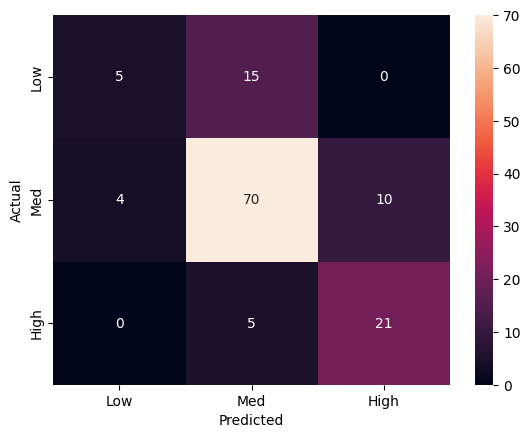

                 Model  Accuracy
0                  DNN  0.738462
1        Random Forest  0.861538
2  Logistic Regression  0.876923


In [ ]:
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score

y_pred = np.argmax(model.predict(X_test_s), axis=1)
print("DNN accuracy:", accuracy_score(y_test, y_pred))
print(classification_report(y_test, y_pred, target_names=["Low","Medium","High"]))

sns.heatmap(confusion_matrix(y_test, y_pred), annot=True, fmt="d",
            xticklabels=["Low","Med","High"], yticklabels=["Low","Med","High"])
plt.xlabel("Predicted"); plt.ylabel("Actual"); plt.show()

comparison = pd.DataFrame({
    "Model": ["DNN", "Random Forest", "Logistic Regression"],
    "Accuracy": [accuracy_score(y_test, y_pred),
                 accuracy_score(y_test, rf_model.predict(X_test_s)),
                 accuracy_score(y_test, lr_model.predict(X_test_s))]
})
print(comparison)

In [ ]:
import joblib
from google.colab import files

model.save("model.keras")
joblib.dump(scaler, "scaler.pkl")
joblib.dump(features, "features.pkl")

files.download("model.keras")
files.download("scaler.pkl")
files.download("features.pkl")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
print(best)

units1     64.000000
units2     32.000000
dropout     0.400000
lr          0.010000
batch      32.000000
val_acc     0.894231
Name: 15, dtype: float64


In [ ]:
print(comparison)

                 Model  Accuracy
0                  DNN  0.738462
1        Random Forest  0.861538
2  Logistic Regression  0.876923


In [ ]:
configs = [(64,32,0.2,0.001,16), (64,32,0.3,0.001,32),
           (32,16,0.2,0.001,16), (128,64,0.3,0.001,32)]

for u1, u2, d, lr, bs in configs:
    accs = []
    for seed in range(3):
        tf.keras.utils.set_random_seed(seed)
        m = build_model(u1, u2, d, lr)
        m.fit(X_train_s, y_train, validation_split=0.2, epochs=300,
              batch_size=bs, callbacks=[early_stop], verbose=0)
        accs.append(accuracy_score(y_test, np.argmax(m.predict(X_test_s, verbose=0), axis=1)))
    print(u1, u2, d, lr, bs, "mean test acc:", round(np.mean(accs), 3))

64 32 0.2 0.001 16 mean test acc: 0.677
64 32 0.3 0.001 32 mean test acc: 0.646
32 16 0.2 0.001 16 mean test acc: 0.569
128 64 0.3 0.001 32 mean test acc: 0.656


In [ ]:
print(X_train_s.shape, X_test_s.shape)
print(y_train.value_counts(normalize=True).round(3))
print("Majority-class baseline:", round(y_test.value_counts(normalize=True).max(), 3))

tf.keras.utils.set_random_seed(0)
m = build_model(64, 32, 0.2, 0.001)
h = m.fit(X_train_s, y_train, validation_split=0.2, epochs=150,
          batch_size=16, verbose=0)   # no early stopping this time
print("epochs run:", len(h.history["loss"]))
print("final train acc:", round(h.history["accuracy"][-1], 3),
      " final val acc:", round(h.history["val_accuracy"][-1], 3))
print("test acc:", round(accuracy_score(
    y_test, np.argmax(m.predict(X_test_s, verbose=0), axis=1)), 3))

(519, 14) (130, 14)
target
1    0.644
2    0.202
0    0.154
Name: proportion, dtype: float64
Majority-class baseline: 0.646
epochs run: 150
final train acc: 0.978  final val acc: 0.837
test acc: 0.854


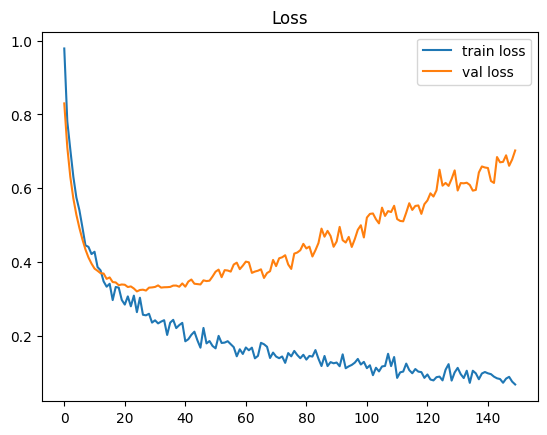

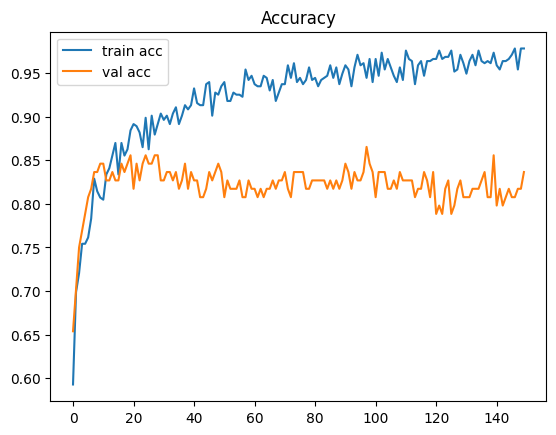

DNN accuracy: 0.8538461538461538
              precision    recall  f1-score   support

         Low       0.83      0.50      0.62        20
      Medium       0.85      0.94      0.89        84
        High       0.88      0.85      0.86        26

    accuracy                           0.85       130
   macro avg       0.85      0.76      0.79       130
weighted avg       0.85      0.85      0.85       130



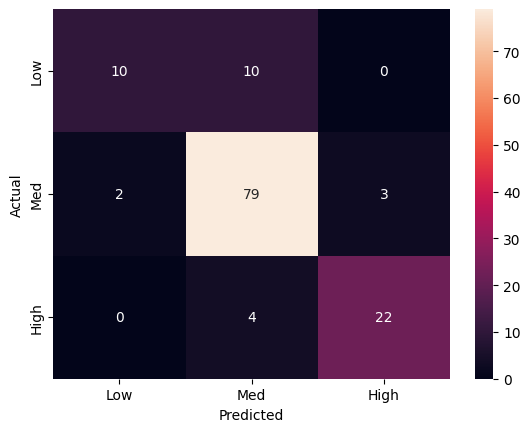

                 Model  Accuracy
0                  DNN  0.853846
1        Random Forest  0.861538
2  Logistic Regression  0.876923


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
import joblib
from google.colab import files

tf.keras.utils.set_random_seed(0)
model = build_model(64, 32, 0.2, 0.001)
history = model.fit(X_train_s, y_train, validation_split=0.2, epochs=150,
                    batch_size=16, verbose=0)

# Loss and accuracy curves
plt.plot(history.history["loss"], label="train loss")
plt.plot(history.history["val_loss"], label="val loss")
plt.legend(); plt.title("Loss"); plt.show()
plt.plot(history.history["accuracy"], label="train acc")
plt.plot(history.history["val_accuracy"], label="val acc")
plt.legend(); plt.title("Accuracy"); plt.show()

# Evaluation
y_pred = np.argmax(model.predict(X_test_s, verbose=0), axis=1)
print("DNN accuracy:", accuracy_score(y_test, y_pred))
print(classification_report(y_test, y_pred, target_names=["Low","Medium","High"]))
sns.heatmap(confusion_matrix(y_test, y_pred), annot=True, fmt="d",
            xticklabels=["Low","Med","High"], yticklabels=["Low","Med","High"])
plt.xlabel("Predicted"); plt.ylabel("Actual"); plt.show()

# Comparison
comparison = pd.DataFrame({
    "Model": ["DNN", "Random Forest", "Logistic Regression"],
    "Accuracy": [accuracy_score(y_test, y_pred),
                 accuracy_score(y_test, rf_model.predict(X_test_s)),
                 accuracy_score(y_test, lr_model.predict(X_test_s))]})
print(comparison)

# Save and download
model.save("model.keras")
joblib.dump(scaler, "scaler.pkl")
joblib.dump(features, "features.pkl")
files.download("model.keras")
files.download("scaler.pkl")
files.download("features.pkl")